# Consider a very back of the envelope scenario to check how transverse galactic accerlation compares with the SGWB


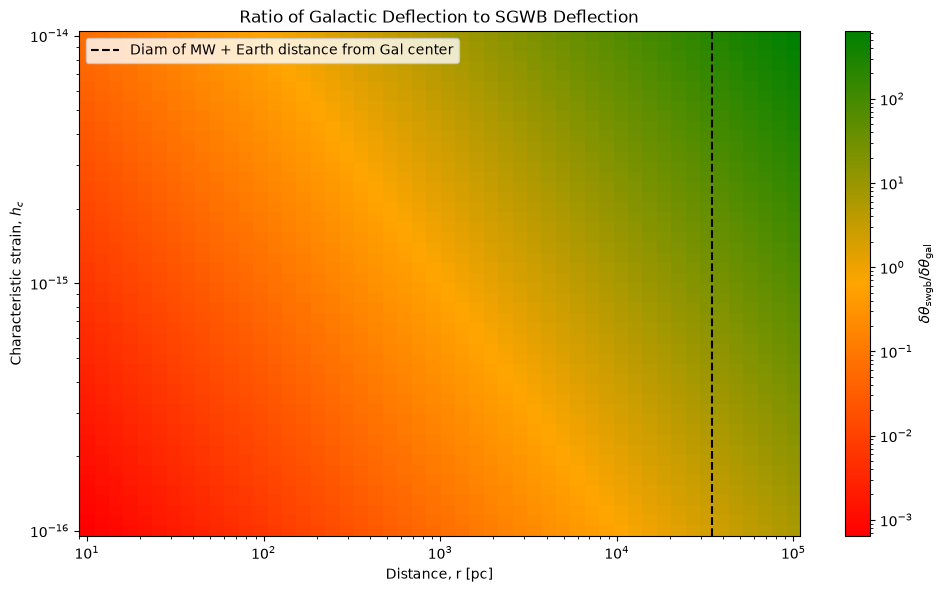

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def delta_theta_gal_res(a_tranv, r, baseline_yrs):
    # assumes a_tranv is in m/s^2, r in pc, and baseline_yrs in yr
    m_per_sec_sqrd_2_pc_per_yrs_sqrd = 3.0856776e-16 / (3.15576e-7)**2
    radiants_2_nas_factor = (206264806247.1)**(1)
    a_tranv = m_per_sec_sqrd_2_pc_per_yrs_sqrd * a_tranv
    return ((1/12) * (a_tranv / r) * baseline_yrs ** 2) * radiants_2_nas_factor

def delta_theta_gal(h_c, baseline_yrs):
    # the deflection due to the SWGB is approximately delta Theta =  T R h_C
    # R (geometric factor) is order unity 
    # T (transfer function) is order unity

    radiants_2_nas_factor = (206264806247.1)**(1)
    return (h_c) * radiants_2_nas_factor


baseline_yrs = 5.5
h_c = np.logspace(-14, -16, 50)
r = np.logspace(1, 5, 50)
a_tranv  = 2e-10 #m/s^2 roughly how our solar system is accerlating around through milkyway
# Ratio: galactic transverse acceleration deflection / SGWB deflection
ratio = (
    delta_theta_gal(h_c[:, None], baseline_yrs) / delta_theta_gal_res(a_tranv, r[None, :], baseline_yrs)
)

# Red -> amber -> green, with logarithmic color scaling
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "red_amber_green",
    ["red", "orange", "green"]
)
norm = plt.matplotlib.colors.LogNorm(
    vmin=np.nanmin(ratio),
    vmax=np.nanmax(ratio)
)

fig, ax = plt.subplots(figsize=(10, 6))

mesh = ax.pcolormesh(
    r,
    h_c,
    ratio,
    cmap=cmap,
    norm=norm,
    shading="auto"
)
d = 7665.0348 + 26800

mesh.set_cmap(cmap)


ax.axvline(
    d,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Diam of MW + Earth distance from Gal center"
)
ax.legend()
ax.set_yscale("log")
ax.set_xlabel("Distance, r [pc]")
ax.set_ylabel(r"Characteristic strain, $h_c$")
ax.set_title("Ratio of Galactic Deflection to SGWB Deflection")

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label(r"$\delta\theta_{\rm swgb}/\delta\theta_{\rm gal}$")

plt.tight_layout()
# plt.show()

ax.set_xscale("log")
ax.set_yscale("log")

fig.canvas.draw()
plt.show()
